# 03. Eksplorasi Tren Korpus dan Karakteristik Linguistik

Notebook ini menjalankan **Tahap 3 metodologi penelitian** langsung dari `data/basic_articles_dataset.csv` dan `data/stopwords.txt` lalu menyimpan seluruh artefak statistik dan leksikon frekuensi ke folder `results/`:
1. **Statistik Kosakata Global**: total token mentah, total token setelah *stopword removal*, tipe kata unik Arab (`[\u0600-\u06FF]+`), tipe kata unik Non-Arab, dan selisih token berulang -> disimpan ke `results/stats/corpus_summary.json` serta berkas `[count]_*.txt`.
2. **Frekuensi N-Gram Teratas (Top-1000 per Kategori)**:
   - *Unigram* setelah *stopword removal* -> disimpan ke `results/stats/nonstop_words/`.
   - *Bigram* dan *Trigram* -> disimpan ke `results/lexicons/bigram_top1000/` dan `results/lexicons/trigram_top1000/`.
3. **Visualisasi**: grafik komposisi kosakata & jumlah token per kategori -> disimpan ke `results/figures/linguistic_stats.png`.


In [1]:
import sys
from pathlib import Path

# Resolve root repositori secara relatif
cwd = Path.cwd().resolve()
REPO_ROOT = cwd if (cwd / "src" / "arabic_news").exists() else cwd.parent
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f"Repository root: {REPO_ROOT.name}")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from arabic_news.acquisition import (
    compute_corpus_distributions,
    compute_token_counts_per_category,
    compute_word_type_counts,
    save_corpus_summary_json,
)
from arabic_news.config import (
    FIGURES_DIR,
    LABELS,
    LABELS_ID,
    LEXICONS_DIR,
    STATS_DIR,
    resolve_data_file,
)
from arabic_news.features import count_top_ngrams_by_category
from arabic_news.preprocessing import (
    load_stopwords,
    preprocess_text,
    reshape_arabic_for_plot,
)

plt.rcParams["figure.dpi"] = 120


Repository root: arabic_news_classification


## 3.1 Komputasi Statistik Global & Token Sebelum vs Sesudah *Stopword Removal*


,Metrik,Nilai
0,Total Baris Mentah,171175
1,Total Artikel Valid (Non-NaN),170934
2,Total Token Korpus (Sebelum Stopword Removal),42661503
3,Total Token Setelah Stopword Removal (Medan Ma...,30559650
4,Tipe Kata Unik Arab,754584
5,Tipe Kata Unik Non-Arab,74727
6,Selisih Token Berulang,41832192


,Label,Kategori,Terjemahan,Artikel Valid,Persentase (%),Artikel Mentah,Baris Kosong,Token Mentah,Token Medan (Tanpa Stopwords)
0,1,أمن,Keamanan,17341,10.1,17341,0,4102495,2958278
1,2,اقتصاد,Ekonomi,15899,9.3,15904,5,3636123,2492920
2,3,تكنولوجيا,Teknologi,11036,6.5,11048,12,2751310,1961766
3,4,ثقافة,Budaya,10844,6.3,10844,0,2086216,1451200
4,5,دوليات,Internasional,17964,10.5,17964,0,5608498,4033241
5,6,رياضة,Olahraga,18612,10.9,18612,0,5476537,3974500
6,7,سياحة,Travel / Pariwisata,18250,10.7,18253,3,5608691,4138059
7,8,سياسة,Politik,18295,10.7,18382,87,3895209,2882240
8,9,صحة,Kesehatan,13260,7.8,13361,101,3004546,2085092
9,10,علم,Sains,14199,8.3,14231,32,3438063,2374822


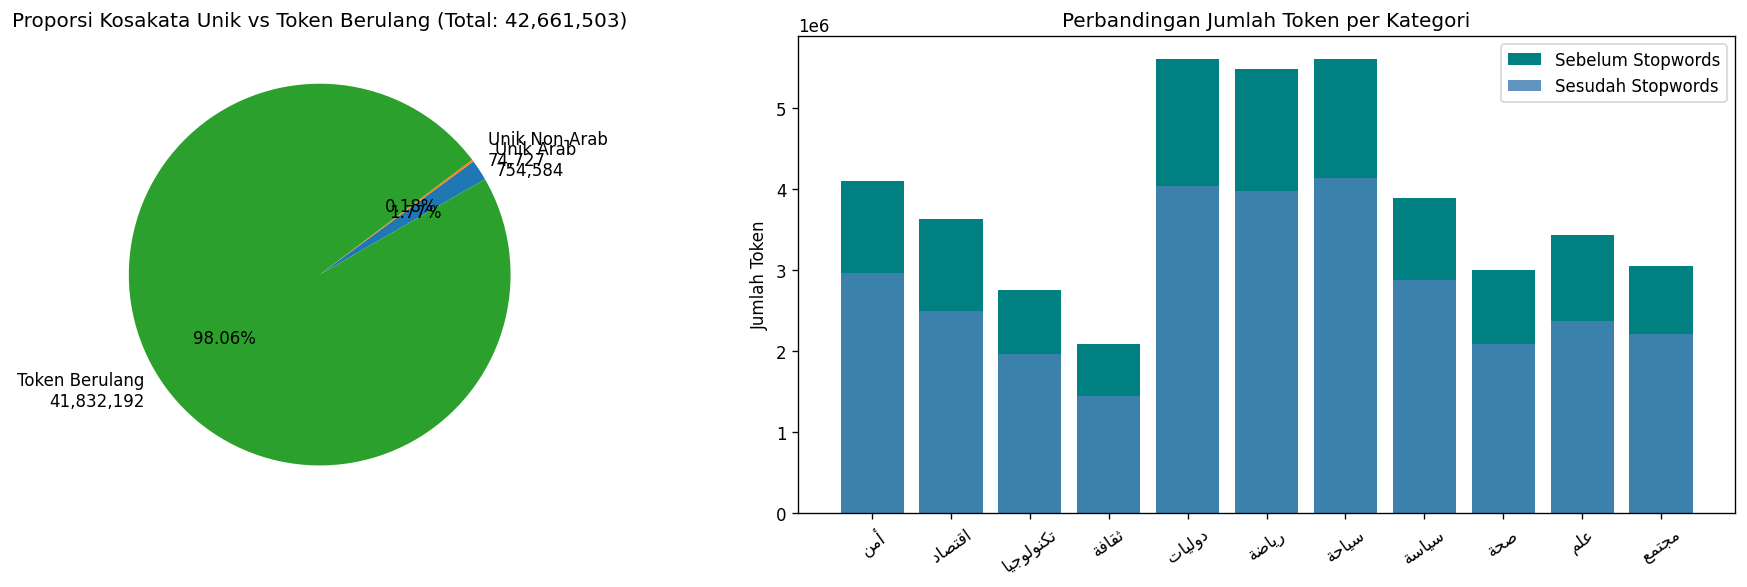

Ringkasan korpus tersimpan ke results/stats/corpus_summary.json


In [2]:
basic_csv = resolve_data_file("basic_articles_dataset.csv")
df_basic = pd.read_csv(basic_csv, low_memory=False)
dists = compute_corpus_distributions(df_basic)
tokens_per_cat = compute_token_counts_per_category(df_basic)
word_types = compute_word_type_counts(df_basic)

# Hitung token setelah penghapusan stopwords (jalur Medan Makna)
stop_set = set(load_stopwords())
valid_df = df_basic.dropna(subset=["text"]).copy()
valid_df["label"] = pd.to_numeric(valid_df["label"], errors="coerce")
valid_df = valid_df.dropna(subset=["label"]).copy()
valid_df["label"] = valid_df["label"].astype(int)
valid_df["medan_text"] = valid_df["text"].astype(str).apply(lambda t: preprocess_text(t, stopwords=stop_set))
nostop_tokens_per_cat = compute_token_counts_per_category(valid_df, text_col="medan_text")

summary_payload = {
    **dists,
    "tokens_per_category": tokens_per_cat,
    "nostop_tokens_per_category": nostop_tokens_per_cat,
    **word_types,
}
summary_path = save_corpus_summary_json(summary_payload)

# Simpan pula berkas statistik per metrik di results/stats/
STATS_DIR.mkdir(parents=True, exist_ok=True)
(STATS_DIR / "[count]_token.txt").write_text(
    "Token Counts per Category:\n" + "\n".join(f"{c}: {tokens_per_cat.get(c, 0)}" for c in LABELS.values()) + "\n",
    encoding="utf-8",
)
(STATS_DIR / "[count]_arabic_types.txt").write_text(
    f"Arabic Word Types Count: {word_types['arabic_word_types']}\n", encoding="utf-8"
)
(STATS_DIR / "[count]_nonarabic_types.txt").write_text(
    f"Non Arabic Word Types Count: {word_types['nonarabic_word_types']}\n", encoding="utf-8"
)

global_summary = pd.DataFrame([
    {"Metrik": "Total Baris Mentah", "Nilai": dists["total_raw_rows"]},
    {"Metrik": "Total Artikel Valid (Non-NaN)", "Nilai": dists["total_valid_articles"]},
    {"Metrik": "Total Token Korpus (Sebelum Stopword Removal)", "Nilai": word_types["total_tokens"]},
    {"Metrik": "Total Token Setelah Stopword Removal (Medan Makna)", "Nilai": sum(nostop_tokens_per_cat.values())},
    {"Metrik": "Tipe Kata Unik Arab", "Nilai": word_types["arabic_word_types"]},
    {"Metrik": "Tipe Kata Unik Non-Arab", "Nilai": word_types["nonarabic_word_types"]},
    {"Metrik": "Selisih Token Berulang", "Nilai": word_types["repeated_tokens_diff"]},
])
display(global_summary)

cat_tok_df = dists["category_distribution"].copy()
cat_tok_df["Token Mentah"] = cat_tok_df["Kategori"].map(tokens_per_cat)
cat_tok_df["Token Medan (Tanpa Stopwords)"] = cat_tok_df["Kategori"].map(nostop_tokens_per_cat)
display(cat_tok_df)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
vocab_labels = [
    f"Unik Arab\n{word_types['arabic_word_types']:,}",
    f"Unik Non-Arab\n{word_types['nonarabic_word_types']:,}",
    f"Token Berulang\n{word_types['repeated_tokens_diff']:,}",
]
axes[0].pie(
    [word_types["arabic_word_types"], word_types["nonarabic_word_types"], word_types["repeated_tokens_diff"]],
    labels=vocab_labels,
    autopct="%1.2f%%",
    startangle=30,
)
axes[0].set_title(f"Proporsi Kosakata Unik vs Token Berulang (Total: {word_types['total_tokens']:,})")

ar_labels = [reshape_arabic_for_plot(c) for c in cat_tok_df["Kategori"]]
axes[1].bar(ar_labels, cat_tok_df["Token Mentah"], color="teal", label="Sebelum Stopwords")
axes[1].bar(ar_labels, cat_tok_df["Token Medan (Tanpa Stopwords)"], color="steelblue", alpha=0.85, label="Sesudah Stopwords")
axes[1].set_title("Perbandingan Jumlah Token per Kategori")
axes[1].set_ylabel("Jumlah Token")
axes[1].tick_params(axis="x", rotation=35)
axes[1].legend()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "linguistic_stats.png", dpi=150)
plt.show()
print(f"Ringkasan korpus tersimpan ke {summary_path.relative_to(REPO_ROOT)}")


## 3.2 Ekstraksi Top-1000 *Unigram*, *Bigram*, dan *Trigram* per Kategori

Menghitung frekuensi *unigram* (sesudah penghapusan *stopwords*), *bigram*, dan *trigram* (retensi preposisi) secara tervektorisasi langsung dari korpus, lalu menyimpan seluruh peringkat Top-1000 tiap kategori ke `results/`.


In [3]:
top_unigrams = count_top_ngrams_by_category(
    valid_df, n=1, text_column="medan_text", top_n=1000, use_regex_tokenizer=False
)
top_bigrams = count_top_ngrams_by_category(
    valid_df, n=2, text_column="text", top_n=1000, use_regex_tokenizer=True
)
top_trigrams = count_top_ngrams_by_category(
    valid_df, n=3, text_column="text", top_n=1000, use_regex_tokenizer=True
)

uni_dir = STATS_DIR / "nonstop_words"
bi_dir = LEXICONS_DIR / "bigram_top1000"
tri_dir = LEXICONS_DIR / "trigram_top1000"
uni_dir.mkdir(parents=True, exist_ok=True)
bi_dir.mkdir(parents=True, exist_ok=True)
tri_dir.mkdir(parents=True, exist_ok=True)

ngram_rows = []
for cid, cname in LABELS.items():
    uni_list = top_unigrams[cname]
    bi_list = top_bigrams[cname]
    tri_list = top_trigrams[cname]

    (uni_dir / f"nonstop_words_{cname}.txt").write_text(
        f"Top {len(uni_list)} Words for {cname}:\n" + "\n".join(f"{w}: {f}" for w, f in uni_list) + "\n",
        encoding="utf-8",
    )
    pd.DataFrame(bi_list, columns=["Bigram N-gram", "Frequency"]).to_csv(
        bi_dir / f"bigram_{cname}.csv", index=False, encoding="utf-8"
    )
    pd.DataFrame(tri_list, columns=["Trigram N-gram", "Frequency"]).to_csv(
        tri_dir / f"trigram_{cname}.csv", index=False, encoding="utf-8"
    )

    ngram_rows.append({
        "Label": cid,
        "Kategori": f"{cname} ({LABELS_ID[cid]})",
        "Top Unigram": uni_list[0][0],
        "Frek. Unigram": uni_list[0][1],
        "Top Bigram": bi_list[0][0],
        "Frek. Bigram": bi_list[0][1],
        "Top Trigram": tri_list[0][0],
        "Frek. Trigram": tri_list[0][1],
    })

display(pd.DataFrame(ngram_rows))
print("Seluruh daftar Top-1000 Unigram, Bigram, dan Trigram berhasil disimpan ke results/.")


,Label,Kategori,Top Unigram,Frek. Unigram,Top Bigram,Frek. Bigram,Top Trigram,Frek. Trigram
0,1,أمن (Keamanan),العراق,22375,السومرية نيوز,14002,السومرية نيوز إن,4799
1,2,اقتصاد (Ekonomi),العام,15961,السومرية نيوز,8379,تلقت السومرية نيوز,2058
2,3,تكنولوجيا (Teknologi),شركة,15772,الهواتف في,8508,أفضل مخترقي الهواتف,8469
3,4,ثقافة (Budaya),الثقافي,7171,مها الهنداوي,4048,هو أقرب إلى,2025
4,5,دوليات (Internasional),قطر,18756,قطاع غزة,9250,وقف إطلاق النار,5383
5,6,رياضة (Olahraga),قطر,39583,كأس العالم,22955,على كأس العالم,9617
6,7,سياحة (Travel / Pariwisata),الساعة,52254,موعد قيامه,47822,موعد قيامه الساعة,47821
7,8,سياسة (Politik),رئيس,30225,السومرية نيوز,27465,لـ السومرية نيوز,5653
8,9,صحة (Kesehatan),كورونا,21831,فيروس كورونا,6665,منظمة الصحة العالمية,2592
9,10,علم (Sains),العالم,5612,إلى أن,4567,مواقع التواصل الاجتماعي,960


Seluruh daftar Top-1000 Unigram, Bigram, dan Trigram berhasil disimpan ke results/.
